# Analyze grayvalue dynamics in membrane

Goal: obtain water content and profile

In [1]:
import json
import os
import socket
host = socket.gethostname()   
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import dask
import dask.array
from matplotlib import cm
from matplotlib.colors import Normalize

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'

elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mpc/homes/fische_r/NAS/DASCOELY/processing'
else:
    print(host+' is not known to the notebook')
    
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)


EC_path = os.path.join(toppath, 'EC_lab_files')

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))
    
segmentation_path = os.path.join(toppath, 'processing', '04_membrane_ML')
registered_path = os.path.join(toppathSSD, '02_abs_registered_3p1D')

px = 2.75e-6
vx = px**3

# fetch githash
import subprocess
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=14)

In [3]:
import pickle

In [4]:
charge_dict_path = os.path.join(toppath, 'processing', 'charge_dict.p')

In [5]:
charge_dict = pickle.load(open(charge_dict_path, 'rb'))

## Experiment with data

In [6]:
sample = '4'
segpath = os.path.join(segmentation_path, sample, sample+'membrane_segmentation.nc')
seg_data = xr.load_dataset(segpath)

In [7]:
regpath = os.path.join(registered_path, '02_'+sample+'_abs_registered_3p1D.nc')
reg_data = xr.open_dataset(regpath)
[ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']
images = [im for im in reg_data.keys() if im[3:7] == 'imag']
images.sort()

In [8]:
reg_data['time'].data

array([   5.0403168,   15.9423185,   75.9663998,  135.9904858,
        196.0145736,  256.0126612,  316.0347477,  376.0538407,
        436.0789287,  496.09301  ,  556.1100972,  616.1251891,
        676.1522715,  736.1663578,  796.1864499,  856.2125368,
        916.238624 ,  976.2557065, 1036.2738   , 1096.2998809,
       1156.3129685, 1216.3430551, 1276.3481419, 1336.3472296,
       1396.3773163, 1456.407404 , 1516.4174912, 1576.4355772,
       1636.4606644, 1696.4857516, 1756.5168375, 1816.5359294,
       1876.5390113, 1936.5640977, 1996.5891855, 2056.6192726,
       2116.6373588, 2176.6674462, 2236.6835322, 2296.7026181,
       2356.7247029, 2416.7327878, 2476.755874 , 2536.7789588,
       2596.808045 , 2656.8391299, 2716.8662156, 2776.8883072,
       2836.9163873, 2896.9454739, 2956.9665598, 3016.9966523,
       3077.0097321, 3136.9968241, 3197.0259045, 3257.0429906,
       3317.065083 , 3377.0881645, 3437.1182508, 3497.1463366,
       3557.1734229,    7.6584655,   67.6875467,  127.6

In [9]:
t_utc_tomo = reg_data['t_utc'].data

In [10]:
a,b,c,d,e,f = seg_data.attrs['cropping of seg data']

In [11]:
seg_data.attrs['cropping of seg data']

array([ 10, -10,  10, -10,  10, -10])

In [12]:
shp = reg_data[images[4]][ar:br, cr:dr, er:fr][a:b,c:d,e:f].shape
# shp = data[images[4]][:, c:d, e:f].shape
shp = shp + (len(images),)

In [13]:
im = np.zeros(shp, dtype = np.uint16)

In [14]:
# with obtained cropping data
for i in range(shp[-1]):
    if i%10 == 0:
        print(i)
    im[...,i] = reg_data[images[i]][ar:br, cr:dr, er:fr][a:b, c:d, e:f].data
    # im[...,i] = data[images[i]][:, c:d, e:f].data

0
10
20
30
40
50
60
70


In [15]:
reg_data.close()

In [16]:
im.shape

(761, 78, 1526, 71)

In [17]:
membrane = seg_data['segmented'][a+10:b-10,c+10:d,e:f]==0 #correction for 4 , check if match

In [18]:
membrane.shape

(761, 78, 1526, 71)

/tmp/ipykernel_2347725/3082780101.py:2: RuntimeWarning: Mean of empty slice
  plt.imshow(np.nanmean(im[295:305,:,200:800,20],axis=0),cmap, vmin = 28000, vmax=45000)


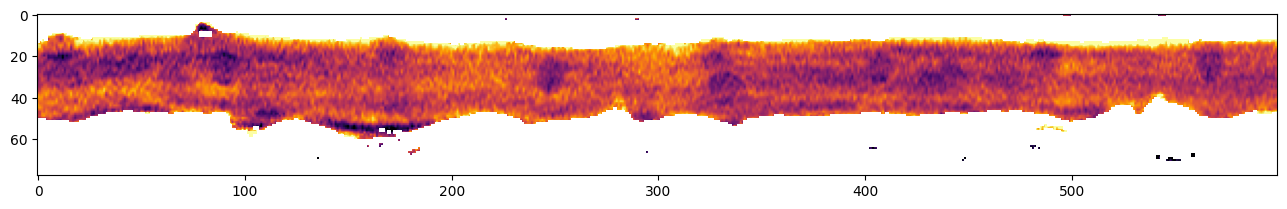

In [71]:
plt.figure(figsize=(16,9))
plt.imshow(np.nanmean(im[295:305,:,200:800,20],axis=0),cmap, vmin = 28000, vmax=45000)
# plt.imshow(membrane[300,:,200:800,20], alpha=0.5, cmap = 'gray')

/tmp/ipykernel_2347725/3256015888.py:1: RuntimeWarning: Mean of empty slice
  plt.hist(np.nanmean(im[295:305,:,200:800,60],axis=0).flatten())


(array([1.3000e+01, 0.0000e+00, 2.0000e+00, 1.0000e+01, 8.6800e+02,
        1.8187e+04, 3.7530e+03, 3.7000e+02, 2.2000e+01, 7.3000e+01]),
 array([1.00000000e+00, 6.55304980e+03, 1.31050996e+04, 1.96571504e+04,
        2.62091992e+04, 3.27612500e+04, 3.93133008e+04, 4.58653516e+04,
        5.24173984e+04, 5.89694492e+04, 6.55215000e+04]),
 <BarContainer object of 10 artists>)

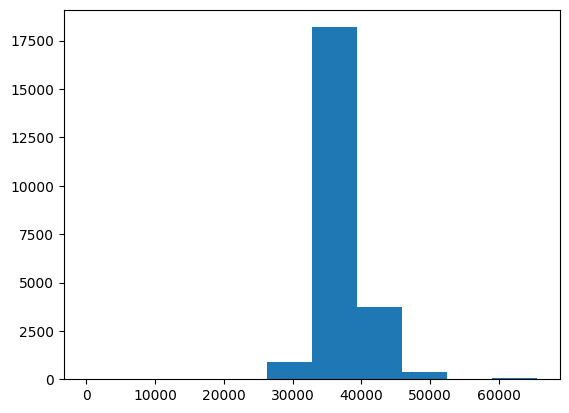

In [64]:
plt.hist(np.nanmean(im[295:305,:,200:800,60],axis=0).flatten())

In [20]:
test = np.ones(membrane.shape, dtype=np.float16)

In [21]:
test[~membrane] = np.nan

In [22]:
im = im*test

## profiles

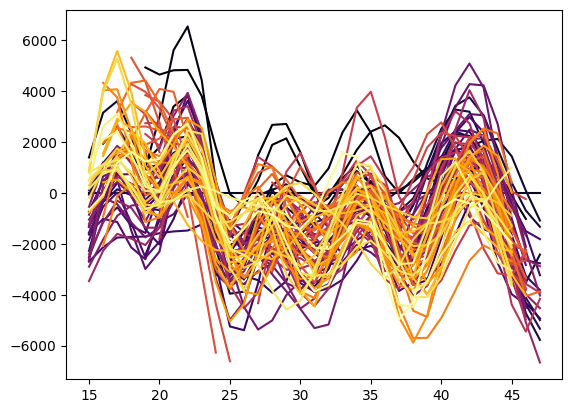

In [36]:
vmin = 0
vmax= im.shape[-1]
cmap = cm.inferno
norm = Normalize(vmin=vmin, vmax=vmax)
prof0 = im[298:302,:, 600, 4].mean(axis = 0)
prof0 = (prof0+np.roll(prof0, 1)+np.roll(prof0, -1))/3
for ts in range(im.shape[-1]):
    prof = im[298:302,:, 600, ts].mean(axis = 0)
    prof = (prof+np.roll(prof, 1)+np.roll(prof, -1))/3
    plt.plot(prof-prof0, color = cmap(norm(ts)))

In [27]:
prof = im[298:302,:, 600, ts].mean(axis = 0)

In [28]:
profsm = (prof+np.roll(prof, 1)+np.roll(prof, -1))/3

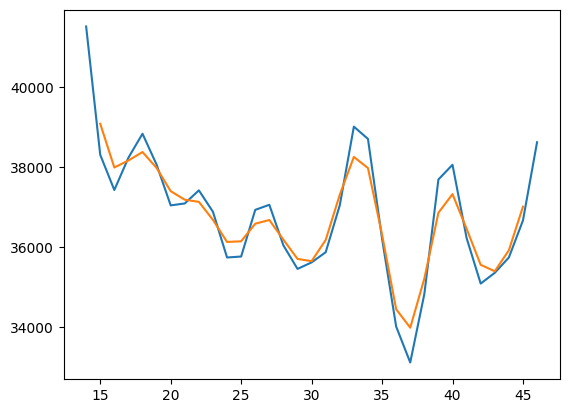

In [29]:
plt.plot(prof)
plt.plot(profsm)

In [38]:
mean_grays = np.nanmean(im, axis = (0,1,2))

In [39]:
med_grays = np.nanmedian(im, axis = (0,1,2))

In [40]:
std_grays = np.nanstd(im, axis = (0,1,2))

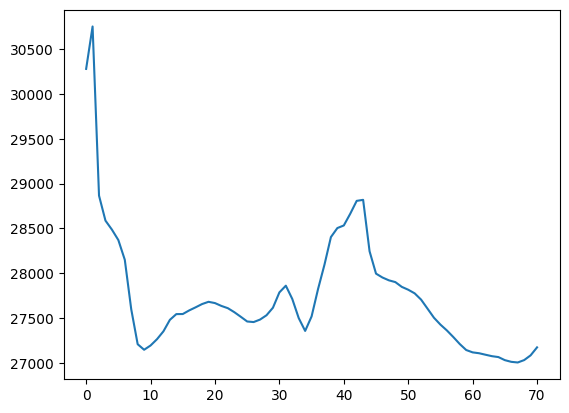

In [41]:
# plt.plot((mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
# plt.plot((med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
plt.plot(mean_grays)

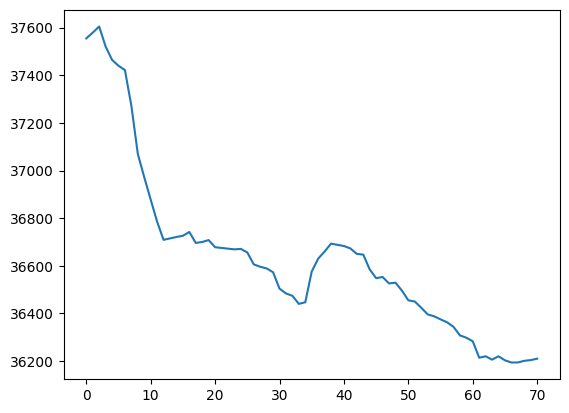

In [42]:
plt.plot(med_grays)

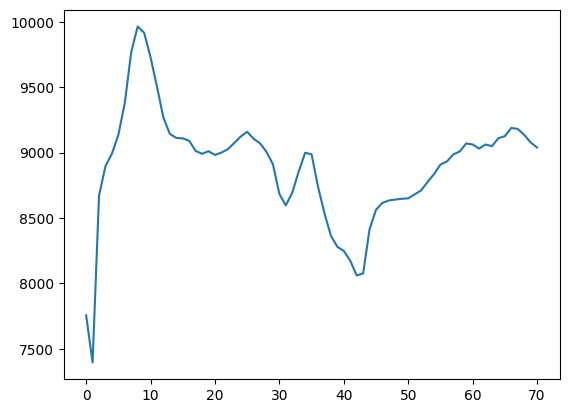

In [43]:
plt.plot(std_grays)

In [44]:
HFR_time = charge_dict[sample]['HFR']['HFRtime']
HFR = charge_dict[sample]['HFR']['fit_HFR']
HFR0 = charge_dict[sample]['HFR']['highfreqR']
t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
sat = charge_dict[sample]['saturation']
TH = charge_dict[sample]['TH']
crack_vol =charge_dict[sample]['crack volume']
memvol = charge_dict[sample]['membrane volume']
rel_swell = memvol/memvol.min()*100
Q = charge_dict[sample]['Q']
I = -charge_dict[sample]['I']
E = -charge_dict[sample]['E']
time = charge_dict[sample]['time']

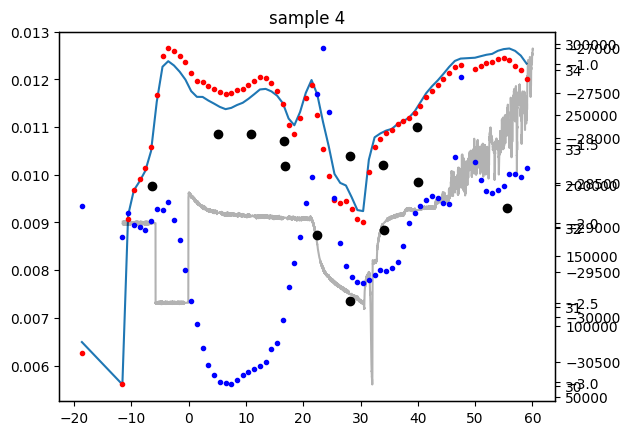

In [50]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.00525,0.013)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
# ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
# ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

# ax6 = ax.twinx()
# ax6.plot(t_tomo/60 - 11.5, memvol, 'g.')

Text(0.5, 1.0, 'sample 4')

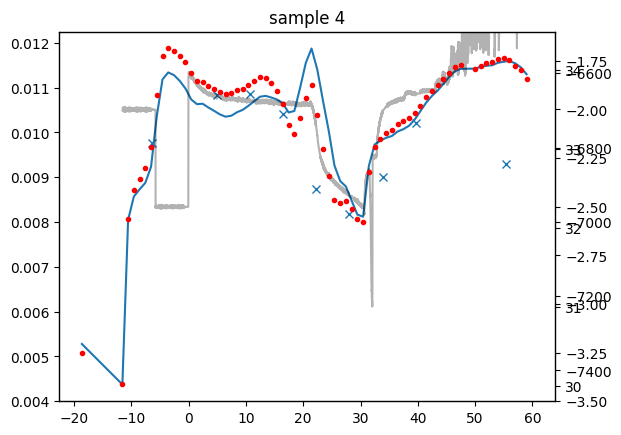

In [79]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.004,0.01225)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
ax3.set_ylim(-3.5,-1.6)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

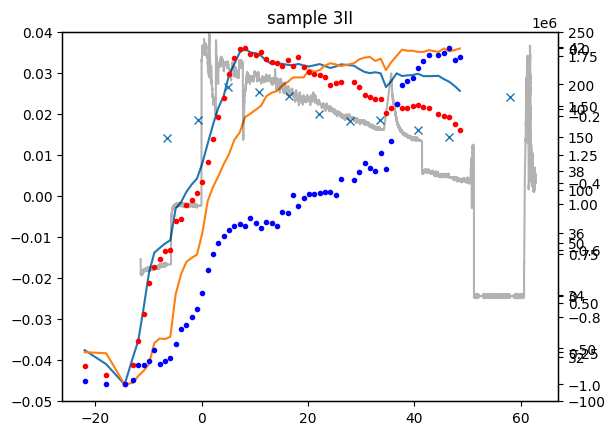

In [49]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(-0.05,0.04)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

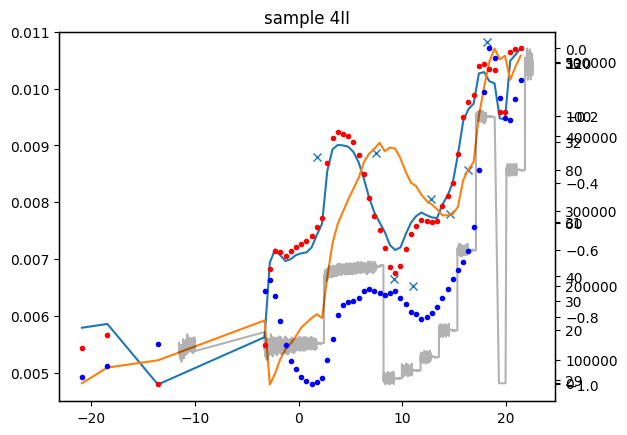

In [34]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.0045,0.011)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

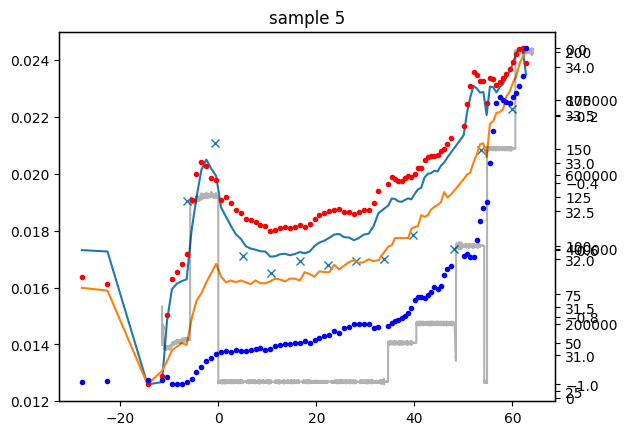

In [36]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

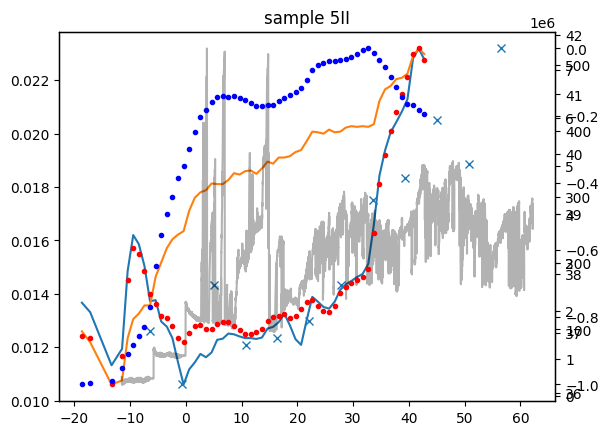

In [28]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
# ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))

# gray mean and thickness are basically the same because paginin filtering considers the propagation distance --> wider objects of same density are darker --> profiles useless, but gray value gives thickness
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

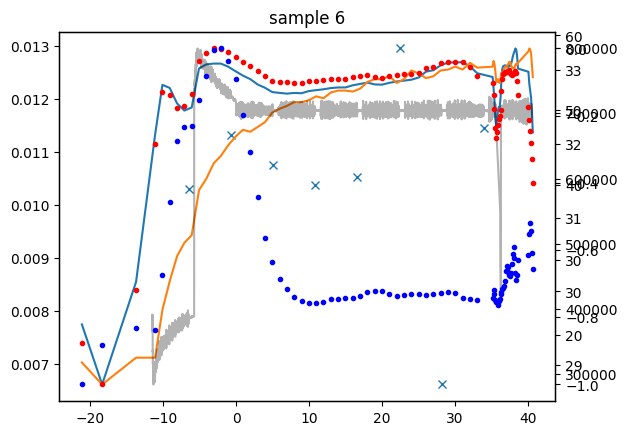

In [27]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
# ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

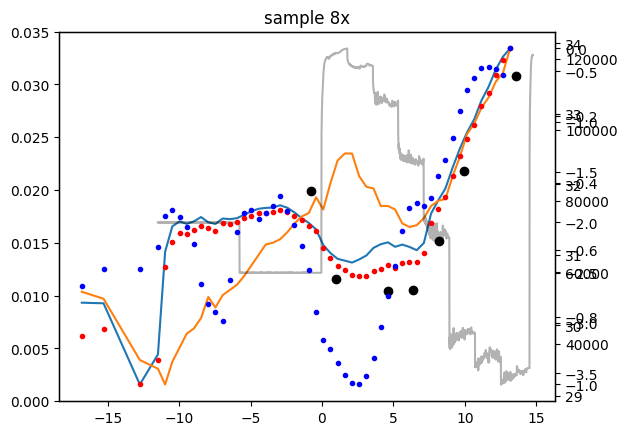

In [37]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.000,0.035)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

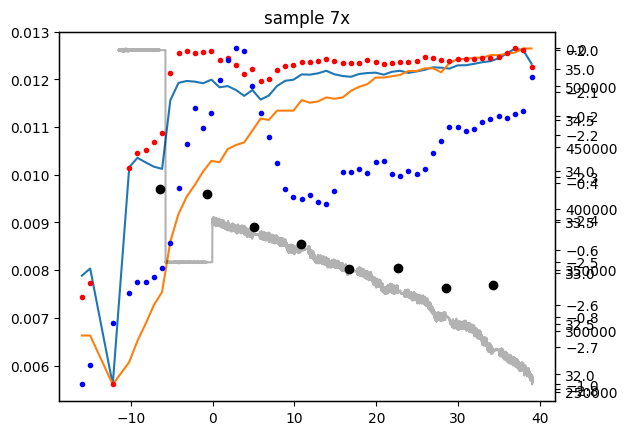

In [34]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.00525,0.013)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

In [22]:
import ctypes
def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

In [32]:
trim_memory()

1